In [1]:
#####################################################
# Imports and Simulation IO
#####################################################
import os 
import numpy as np
from MDToolkit.data.objects import Topology, Frame, Simulation, LAMMPS_CustomDump_Reader
from MDToolkit.utils.structure_file_utils import create_elements_dictionary
from MDToolkit.utils.misc_utils import get_n_even_chunks
from MDToolkit.analysis.diffusivity import compute_msd, compute_diffusivity

molarity = 0.1
ensemble = 3

# filedir = f"/media/jrjoseph/Elements/projects/fem_memristor/md_simulations/cscl_diffusivity_ls6/{molarity}M/"
filedir = f"/media/jrjoseph/Elements/projects/fem_memristor/md_simulations/cscl_{molarity}M_ls6/v{ensemble}"
filename = f"cscl_{molarity}M_water_prod{ensemble}.out"

filepath = os.path.join(filedir, filename)

type_mapping = {
    1 : "C",
    2 : "Cl",
    3 : "H",
    4 : "Cs",
    5 : "O",
}

topol = Topology(type_mapping, elements_dict = create_elements_dictionary())

simulation = Simulation(filepath, topol, LAMMPS_CustomDump_Reader, cpp_init=False)

ion_spcs = ["Cs", "Cl"]

/workspace/miniforge/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
#####################################################
# Plotting Functions
#####################################################

import matplotlib.pyplot as plt
from matplotlib.patches import Patch

def plot_msd(
    msd_data,
    ion_spcs,
    ax=None
):
    '''
    Plot x, y, and z MSD for each ion species.
    '''
    if ax is None:
        fig, ax = plt.subplots()

    t = msd_data["timesteps"]

    for ion_spc in ion_spcs:

        msd = msd_data[ion_spc]

        labels = [
            rf"{ion_spc} MSD"
        ]

        for i, label in enumerate(labels):

            ax.plot(
                t,
                msd,
                lw=2,
                label=label
            )

    ax.set_xlabel("Time Step")
    ax.set_ylabel(r"MSD ($\mathrm{\AA^2}$)")

    ax.legend(
        frameon=False,
        ncol=2,
        loc="best"
    )

    plt.show()

    return ax


def plot_block_averaged_msd(
    msd_data,
    ion_spcs,
    n=10,
    ax=None
):
    '''
    Plot MSD averaged over n blocks.
    '''

    if ax is None:
        fig, ax = plt.subplots()

    t = msd_data["timesteps"]

    blocks = get_n_even_chunks(
        range(len(t)),
        n_chunks=n
    )

    for ion_spc in ion_spcs:

        block_msds = []

        for block in blocks:

            block = np.array(block)

            block_msd = msd_data[ion_spc][block]
            block_msd = block_msd - block_msd[0]

            block_msds.append(
                block_msd
            )

        mean_msd = np.mean(
            block_msds,
            axis=0
        )

        block_t = t[blocks[0]]
        block_t = block_t - block_t[0]

        std_msd = np.std(block_msds, axis=0)

        ax.plot(
            block_t,
            mean_msd,
            lw=2,
            label=ion_spc
        )

        ax.fill_between(block_t, mean_msd - std_msd, mean_msd + std_msd, alpha=0.2)

    ax.set_xlabel("Time Step")
    ax.set_ylabel(r"MSD ($\mathrm{\AA^2}$)")

    ax.legend(
        frameon=False,
        ncol=2,
        loc="best"
    )

    plt.show()

    return ax

In [3]:
msd_data = compute_msd(simulation, ion_spcs)

100%|██████████| 20001/20001 [01:07<00:00, 295.23it/s]


In [5]:
from MDToolkit.IO.write_file import export_numeric_data

print(msd_data)

export_numeric_data(msd_data, f"CsCl_{molarity}M_run{ensemble}_MSD.csv", file_path=filedir + "/../")

{'timesteps': array([       0,     1000,     2000, ..., 19998000, 19999000, 20000000],
      shape=(20001,)), 'Cs': array([0.00000000e+00, 2.28908389e+00, 4.16815490e+00, ...,
       3.22456217e+04, 3.22551021e+04, 3.22566531e+04], shape=(20001,)), 'Cl': array([0.00000000e+00, 1.41165495e+00, 2.73939102e+00, ...,
       2.22957228e+04, 2.22838105e+04, 2.22243829e+04], shape=(20001,))}
CSV file written to: /media/jrjoseph/Elements/projects/fem_memristor/md_simulations/cscl_0.1M_ls6/v3/../CsCl_0.1M_run3_MSD.csv


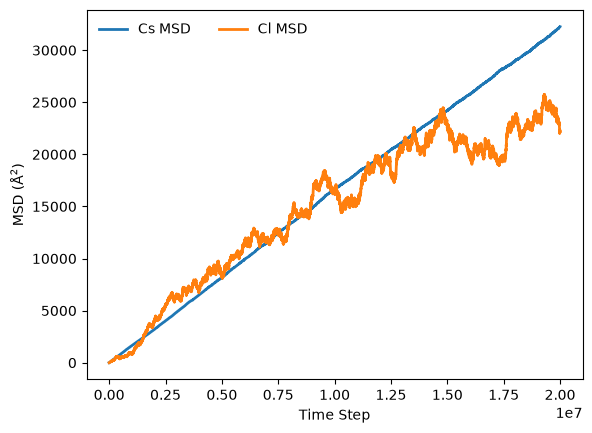

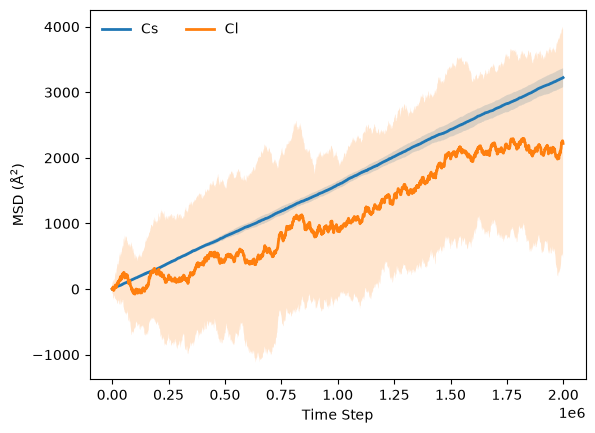

<Axes: xlabel='Time Step', ylabel='MSD ($\\mathrm{\\AA^2}$)'>

In [ ]:
plot_msd(msd_data, ion_spcs)
n_blocks = 10
plot_block_averaged_msd(msd_data, ion_spcs, n_blocks)

In [ ]:
# Diffusivity from MSD

diffusivities = compute_diffusivity(msd_data, ion_spcs, n_blocks)
# Å²/fs -> m²/s
conversion = 1e15 / 1e20

for ion in ion_spcs:
    print(f"{ion} D (m²/s): {diffusivities[ion]['mean'] * conversion}")
    print(f"{ion} D std dev: {diffusivities[ion]['std'] * conversion}")

Cs D (m²/s): 2.7033463271522183e-09
Cs D std dev: 1.280378754477195e-10
Cl D (m²/s): 2.1169202445395577e-09
Cl D std dev: 1.5547159743130587e-09
